## COMP661 Assignment 3 Canterbury Temperature forecasting 1174130 Ken Livingston

**Part 1:  EDA and pre-processing**

In this section we'll build in the spatial relationships between the weather stations.  As we found in Parts 1 and 2, Hanmer Forest is something of an outlier and we'll see if we can correct this by adjusting for distance and by using each station's unified data to build the forecasting model to predict temperatures up to 7 days ahead.  We'll use the settings from Part 2 as the basis for the models in this section.

In [19]:
# Import the libraries
import itertools
import joblib
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns
import time
import torch
import torch.nn as nn

from IPython.display import Markdown, display
from pathlib import Path

In [20]:
# Set up the common parameters
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path("..", "..")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PART1_MODEL_DIR = PROJECT_ROOT / "Part_1" / "models"
PART2_MODEL_DIR = PROJECT_ROOT / "Part_2" / "models"
FIG_DIR = Path("..", "figures")
MODEL_DIR = Path("..", "models")
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

RERUN_EXPERIMENTS = False

# Define Station names, IDs, data folders and coordinates (from Table 1 of the assignment brief)
STATION_INFO = {
    "Christchurch Aero": {"id": "4843",  "folder": "christchurch_aero",        "lat": -43.493, "lon": 172.537},
    "Chch Kyle Street":  {"id": "24120", "folder": "christchurch_kyle_st_ews", "lat": -43.531, "lon": 172.608},
    "Ashburton Aero":    {"id": "26170", "folder": "ashburton_aero_aws",       "lat": -43.903, "lon": 171.804},
    "Rangiora":          {"id": "17244", "folder": "rangiora_ews",             "lat": -43.329, "lon": 172.611},
    "Hanmer Forest":     {"id": "11234", "folder": "hanmer_forest_ews",        "lat": -42.534, "lon": 172.851},
}
STATIONS = list(STATION_INFO)
N_NODES = len(STATIONS)

FEATURES = ["evap_penman_ow", "evap_penman_pet", "evap_pt_pet",
            "max_temp", "min_temp", "mean_temp", "wind_speed", "rainfall"]
TARGET = "mean_temp"
TARGET_IDX = FEATURES.index(TARGET)
HORIZON = 7

# Settings from Part 2
part2_config = json.loads((PART2_MODEL_DIR / "final_model_config.json").read_text())
WINDOW = part2_config["window_days"]            # look-back window selected in Part 2
CELL_TYPE = part2_config["cell_type"]           # recurrent cell selected in Part 2
HIDDEN_SIZE, NUM_LAYERS, DROPOUT = part2_config["hidden_size"], part2_config["num_layers"], part2_config["dropout"]
BATCH_SIZE, LEARNING_RATE, MAX_EPOCHS, PATIENCE = 64, 1e-3, 100, 10
SEEDS = [0, 1, 2]
DEVICE = torch.device("cpu")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

# Table settings
def column_decimals(column, max_decimals=3):
    values = column.dropna().abs()
    for decimals in range(max_decimals + 1):
        if np.allclose(values, values.round(decimals)):
            return decimals
    return max_decimals

def show_table(table, title, max_decimals=3):
    display(Markdown(f"**{title}**"))
    float_columns = table.select_dtypes("float").columns
    number_formats = {col: f"{{:.{column_decimals(table[col], max_decimals)}f}}" for col in float_columns}
    display(table.style.format(number_formats))

print(f"Settings from Part 2: {CELL_TYPE} cell, {WINDOW}-day window, {NUM_LAYERS} layers × {HIDDEN_SIZE} units, "
      f"dropout {DROPOUT}")

Settings from Part 2: GRU cell, 60-day window, 2 layers × 64 units, dropout 0.2


**3.1 Graph Construction Using Inter-Station Distance**
To get the distance between each station we'll use the haversine formula, which calculates the great circle distance between two points on a sphere from their latitude
and longitude, then convert the results to kilometres.

In [21]:
EARTH_RADIUS_KM = 6389.0    # As at Christchurch sea level

def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between two points given in decimal degrees."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))


distance_km = pd.DataFrame(0.0, index=STATIONS, columns=STATIONS)
for a, b in itertools.combinations(STATIONS, 2):
    d = haversine_km(STATION_INFO[a]["lat"], STATION_INFO[a]["lon"], STATION_INFO[b]["lat"], STATION_INFO[b]["lon"])
    distance_km.loc[a, b] = distance_km.loc[b, a] = d
pair_distances = distance_km.to_numpy()[np.triu_indices(N_NODES, k=1)]
show_table(distance_km.round(1), "Table 3.1 – Haversine distance between stations (km)")
print(f"10 station pairs: mean distance {pair_distances.mean():.1f} km, std {pair_distances.std():.1f} km, "
      f"range {pair_distances.min():.1f}–{pair_distances.max():.1f} km")

**Table 3.1 – Haversine distance between stations (km)**

,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
Christchurch Aero,0.0,7.1,74.7,19.2,110.0
Chch Kyle Street,7.1,0.0,76.9,22.5,112.9
Ashburton Aero,74.7,76.9,0.0,91.3,174.8
Rangiora,19.2,22.5,91.3,0.0,90.8
Hanmer Forest,110.0,112.9,174.8,90.8,0.0


10 station pairs: mean distance 78.0 km, std 48.5 km, range 7.1–174.8 km


Use the distances to calculate edge weights.

Closer stations should influence each other more, so each distance is turned into a similarity between 0 and 1, calculated with a Gaussian kernel that uses a scale (sigma) that controls how quickly influence decays with distance. We'll try two values for scale:
* mean pairwise distance (78.0km): which means every station will keep a noticeable link to every other.
* standard deviation of the distances (48.5km): which will make the graph much more local, with Hanmer Forest almost cut off.

All 10 edges are kept, so the graph remains fully connected and undirected (the weight matrix is symmetric). For the graph layers, we'll normalise each row (each row is divided by its sum). Each node then receives a weighted average of its neighbours' information rather than a sum, so nodes with more or stronger links do not get larger inputs.

In [22]:
def edge_weights(sigma_km):
    """Symmetric Gaussian-kernel weights (no self-loops)."""
    weights = np.exp(-(distance_km.to_numpy() / sigma_km) ** 2)
    np.fill_diagonal(weights, 0.0)
    return weights

def normalised_adjacency(weights):
    """Row-normalised adjacency: each node averages its neighbours with weights summing to 1."""
    return weights / weights.sum(axis=1, keepdims=True)

SIGMA_OPTIONS = {"mean": pair_distances.mean(), "std": pair_distances.std()}
weights_mean_sigma = pd.DataFrame(edge_weights(SIGMA_OPTIONS["mean"]), index=STATIONS, columns=STATIONS)
show_table(weights_mean_sigma.round(3), f"Table 3.2 – Edge weights w_ij with σ = mean distance "
                                        f"({SIGMA_OPTIONS['mean']:.1f} km)")
show_table(pd.DataFrame(normalised_adjacency(weights_mean_sigma.to_numpy()), index=STATIONS, columns=STATIONS).round(3),
           "Table 3.3 – Row-normalised adjacency used by the graph layers (σ = mean distance); "
           "each row shows how much each neighbour contributes to that station")
show_table(pd.DataFrame(edge_weights(SIGMA_OPTIONS["std"]), index=STATIONS, columns=STATIONS).round(3),
           f"Table 3.4 – Edge weights w_ij with σ = standard deviation of distances ({SIGMA_OPTIONS['std']:.1f} km)")

**Table 3.2 – Edge weights w_ij with σ = mean distance (78.0 km)**

,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
Christchurch Aero,0.000,0.992,0.400,0.941,0.137
Chch Kyle Street,0.992,0.000,0.378,0.920,0.123
Ashburton Aero,0.400,0.378,0.000,0.254,0.007
Rangiora,0.941,0.920,0.254,0.000,0.258
Hanmer Forest,0.137,0.123,0.007,0.258,0.000


**Table 3.3 – Row-normalised adjacency used by the graph layers (σ = mean distance); each row shows how much each neighbour contributes to that station**

,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
Christchurch Aero,0.000,0.402,0.162,0.381,0.056
Chch Kyle Street,0.411,0.000,0.157,0.381,0.051
Ashburton Aero,0.385,0.364,0.000,0.245,0.006
Rangiora,0.396,0.388,0.107,0.000,0.109
Hanmer Forest,0.261,0.234,0.013,0.492,0.000


**Table 3.4 – Edge weights w_ij with σ = standard deviation of distances (48.5 km)**

,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
Christchurch Aero,0.000,0.979,0.093,0.854,0.006
Chch Kyle Street,0.979,0.000,0.081,0.806,0.004
Ashburton Aero,0.093,0.081,0.000,0.029,0.000
Rangiora,0.854,0.806,0.029,0.000,0.030
Hanmer Forest,0.006,0.004,0.000,0.030,0.000


Table 3.2 shows how edge weight drops quickly with distance between stations, even more so when using a normalised adjustment for distances (Tables 3.3 and 3.4).

Let's see how that looks spacially - with edge weights shown as line thickness.

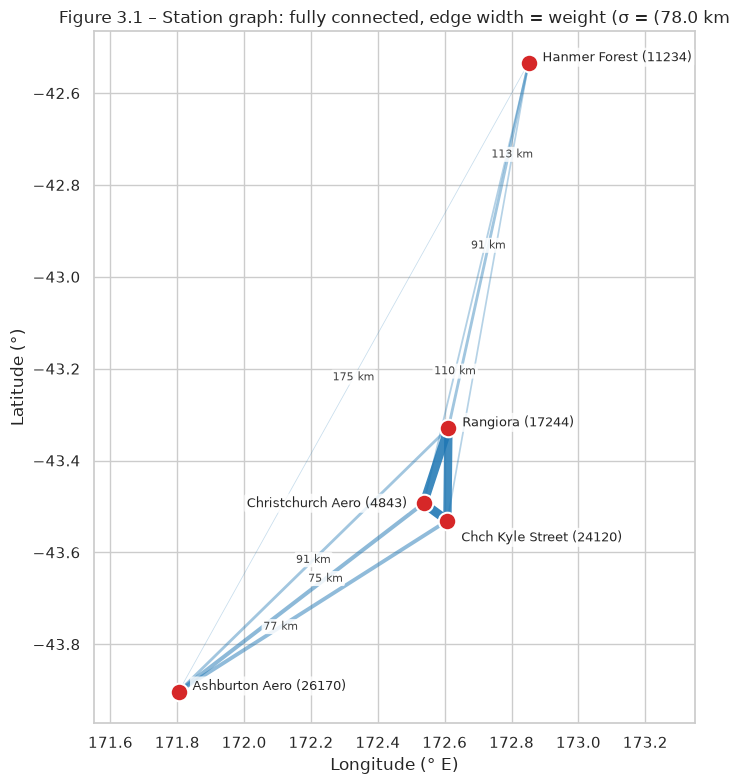

In [ ]:
# Position of each distance label along its edge (0 = first station, 1 = second, etc.), chosen to avoid overlaps
label_position = {("Christchurch Aero", "Hanmer Forest"): 0.30, ("Chch Kyle Street", "Hanmer Forest"): 0.80,
                  ("Rangiora", "Hanmer Forest"): 0.5, ("Christchurch Aero", "Ashburton Aero"): 0.40,
                  ("Chch Kyle Street", "Ashburton Aero"): 0.62, ("Ashburton Aero", "Rangiora"): 0.5,
                  ("Ashburton Aero", "Hanmer Forest"): 0.5}
# Offset and alignment of each station's name label
name_offset = {"Christchurch Aero": (-12, 0, "right"), "Chch Kyle Street": (10, -12, "left"),
               "Ashburton Aero": (10, 4, "left"), "Rangiora": (10, 4, "left"), "Hanmer Forest": (10, 4, "left")}

fig, ax = plt.subplots(figsize=(8, 8))
for a, b in itertools.combinations(STATIONS, 2):
    w = weights_mean_sigma.loc[a, b]
    xa, ya, xb, yb = STATION_INFO[a]["lon"], STATION_INFO[a]["lat"], STATION_INFO[b]["lon"], STATION_INFO[b]["lat"]
    ax.plot([xa, xb], [ya, yb], color="#1f77b4", lw=0.5 + 6 * w, alpha=0.25 + 0.65 * w, zorder=1)
    if (a, b) in label_position:                      # short edges (7–23 km) are listed in Table 3.1 instead
        f = label_position[(a, b)]
        ax.text(xa + f * (xb - xa), ya + f * (yb - ya), f"{distance_km.loc[a, b]:.0f} km", fontsize=8, color="0.25",
                ha="center", va="center", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
for station, info in STATION_INFO.items():
    dx, dy, align = name_offset[station]
    ax.scatter(info["lon"], info["lat"], s=160, color="#d62728", zorder=3, edgecolor="white", lw=1.5)
    ax.annotate(f"{station} ({info['id']})", (info["lon"], info["lat"]), xytext=(dx, dy), textcoords="offset points",
                fontsize=9, ha=align, va="center", zorder=4,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
ax.set_xlabel("Longitude (° E)")
ax.set_ylabel("Latitude (°)")
ax.set_aspect(1 / np.cos(np.radians(-43.3)))      # equal ground distance on both axes
ax.set_xlim(171.55, 173.35)
ax.set_title("Figure 3.1 – Station graph: fully connected, edge width = weight (σ = " f"({SIGMA_OPTIONS['mean']:.1f} km))")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_station_graph.png", dpi=150)
plt.show()

Each station receives information from every other station, but clearly much less the further away it is from the other.

**3.2 Node Features**
We'll used the combined data file with all the features for all the stations, using the same look-back window size of 60 days (from Part 2) to forecast the next 7 days for each node.  Since each station has a slightly different range, we'll scale for each station so that they can be more consistent across all stations.

In [24]:
station_data = {}
for station, info in STATION_INFO.items():
    df = pd.read_csv(PROCESSED_DIR / f"{info['folder']}_daily_clean.csv", parse_dates=["date"])
    station_data[station] = df.set_index("date")[FEATURES]
dates = station_data[STATIONS[0]].index
assert all(station_data[s].index.equals(dates) for s in STATIONS), "station calendars must match"

split_dates = {name: [pd.Timestamp(d) for d in ds]
               for name, ds in json.loads((PART1_MODEL_DIR / "split_dates.json").read_text()).items()}
station_scalers = joblib.load(PART1_MODEL_DIR / "feature_scalers.joblib")

# Stack scaled features into one array: [days, nodes, features]
scaled_all = np.stack([station_scalers[s].transform(station_data[s][FEATURES]) for s in STATIONS], axis=1)
TARGET_MEAN = np.array([station_scalers[s].mean_[TARGET_IDX] for s in STATIONS])
TARGET_STD = np.array([station_scalers[s].scale_[TARGET_IDX] for s in STATIONS])

def make_graph_windows(scaled, window, split_name):
    first_day, last_day = split_dates[split_name]
    X, y, target_start = [], [], []
    for t in range(window - 1, len(dates) - HORIZON):
        if dates[t + 1] < first_day or dates[t + HORIZON] > last_day:
            continue
        X.append(scaled[t - window + 1: t + 1])
        y.append(scaled[t + 1: t + 1 + HORIZON, :, TARGET_IDX].T)
        target_start.append(dates[t + 1])
    return (torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(y), dtype=torch.float32),
            pd.DatetimeIndex(target_start))

data_splits = {split: make_graph_windows(scaled_all, WINDOW, split) for split in ["train", "validation", "test"]}
show_table(pd.DataFrame({split: {"samples": len(X), "X shape": str(tuple(X.shape)), "y shape": str(tuple(y.shape))}
                         for split, (X, y, _) in data_splits.items()}).T,
           "Table 3.5 – Graph samples per split (X: samples × days × nodes × features; y: samples × nodes × days)")
show_table(pd.DataFrame({"mean_temp training mean (°C)": TARGET_MEAN, "mean_temp training std (°C)": TARGET_STD},
                        index=STATIONS).round(2),
           "Table 3.6 – Per-station scaling of the target (from each station's training period, Part 1)")

**Table 3.5 – Graph samples per split (X: samples × days × nodes × features; y: samples × nodes × days)**

,samples,X shape,y shape
train,4941,"(4941, 60, 5, 8)","(4941, 5, 7)"
validation,1067,"(1067, 60, 5, 8)","(1067, 5, 7)"
test,1068,"(1068, 60, 5, 8)","(1068, 5, 7)"


**Table 3.6 – Per-station scaling of the target (from each station's training period, Part 1)**

,mean_temp training mean (°C),mean_temp training std (°C)
Christchurch Aero,11.67,4.93
Chch Kyle Street,12.64,4.84
Ashburton Aero,11.21,4.91
Rangiora,11.80,4.72
Hanmer Forest,10.32,5.37


The split date ranges are exactly the same as Part 2.  The variations in the mean temperatures and standard deviations show the biases between the stations that came up in Part 2, that we should be able to resolve in this section by training on each station's data.

**3.3 GNN + RNN Model Architecture**

There are two ways we can approach the relationships between stations:
1. Process for geographical distribution (spatial) first, then by time series (temporal), or 
2. Temporal for each station and then adjust for spacial distribution.

We'll try both, to see what the difference might be.  Hanmer will be the station to look out for given that it's the most distant, to see if there are significant differences between the order of processing.

The same GRU, graph layer and head weights are shared by all five stations. The model will learn one set of rules, which the graph adapts to each station's neighbourhood.

In [25]:
class GraphLayer(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.self_linear = nn.Linear(in_dim, out_dim)
        self.neighbour_linear = nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, h, adjacency):
        # h: [..., nodes, in_dim]; adjacency: [nodes, nodes]
        neighbour_mean = torch.einsum("ij,...jd->...id", adjacency, h)
        return torch.relu(self.self_linear(h) + self.neighbour_linear(neighbour_mean))

class GNNRNNForecaster(nn.Module):  # GRU + graph layers, forecasting 7 days at every node
    def __init__(self, order, n_graph_layers, adjacency, n_features=len(FEATURES), hidden=HIDDEN_SIZE,
                 rnn_layers=NUM_LAYERS, dropout=DROPOUT, horizon=HORIZON):
        super().__init__()
        assert order in ("T->S", "S->T")
        self.order = order
        self.register_buffer("adjacency", torch.tensor(adjacency, dtype=torch.float32))
        gru_input = hidden if order == "S->T" else n_features
        if order == "S->T":
            dims = [n_features] + [hidden] * n_graph_layers
            self.graph_layers = nn.ModuleList(GraphLayer(dims[k], dims[k + 1]) for k in range(n_graph_layers))
        else:
            self.graph_layers = nn.ModuleList(GraphLayer(hidden, hidden) for _ in range(n_graph_layers))
        self.gru = nn.GRU(gru_input, hidden, num_layers=rnn_layers, dropout=dropout, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, horizon)

    def encode_time(self, x):   # Run the shared GRU over each node's sequence
        batch, window, nodes, dim = x.shape
        sequences = x.permute(0, 2, 1, 3).reshape(batch * nodes, window, dim)
        output, _ = self.gru(sequences)
        return output[:, -1].reshape(batch, nodes, -1)

    def forward(self, x):
        if self.order == "S->T":
            h = x
            for k, layer in enumerate(self.graph_layers):
                update = layer(h, self.adjacency)
                h = update if k == 0 else h + update
            h = self.encode_time(h)
        else:
            h = self.encode_time(x)
            for layer in self.graph_layers:
                h = h + self.dropout(layer(h, self.adjacency))
        return self.head(h)


demo_model = GNNRNNForecaster("T->S", 1, normalised_adjacency(edge_weights(SIGMA_OPTIONS["mean"])))
demo_out = demo_model(data_splits["train"][0][:4])
print("Forward-pass check: input", tuple(data_splits["train"][0][:4].shape), "→ output", tuple(demo_out.shape))
param_rows = {}
for order, layers in [("T->S", 1), ("T->S", 2), ("S->T", 1), ("S->T", 2)]:
    m = GNNRNNForecaster(order, layers, np.zeros((N_NODES, N_NODES)))
    param_rows[f"{order}, {layers} graph layer(s)"] = sum(p.numel() for p in m.parameters())
show_table(pd.DataFrame({"trainable parameters": param_rows}), "Table 3.7 – Model sizes")

Forward-pass check: input (4, 60, 5, 8) → output (4, 5, 7)


**Table 3.7 – Model sizes**

,trainable parameters
"T->S, 1 graph layer(s)",47879
"T->S, 2 graph layer(s)",56135
"S->T, 1 graph layer(s)",51463
"S->T, 2 graph layer(s)",59719


The check passes a small batch of 4 samples, each holding 60 days × 5 stations × 8 features, and gets back 4 × 5 × 7 (days of) forecasts. The models are small (around 48,000 to 60,000 parameters). Most parameters sit in the 2-layer GRU.

**3.4 Training and Evaluation**

Training is the same as in Part 2:  We'll use MSE loss over all 5 nodes × 7 days (in each station's scaled units), Adam with learning rate 0.001, mini-batches of 64 samples (each containing all 5 stations), shuffled sample order, and early stopping on the validation loss with patience 10. Model selection will use the mean validation RMSE in °C over the five stations.

In [26]:
def predict(model, X, batch_size=256):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(X[i:i + batch_size]) for i in range(0, len(X), batch_size)])

def to_celsius(scaled_targets):
    return scaled_targets * TARGET_STD[None, :, None] + TARGET_MEAN[None, :, None]

def validation_rmse_by_node(model):
    X_val, y_val, _ = data_splits["validation"]
    errors = to_celsius(predict(model, X_val).numpy()) - to_celsius(y_val.numpy())
    return np.sqrt((errors ** 2).mean(axis=(0, 2)))           # one RMSE per node

def train_graph_model(order, n_graph_layers, adjacency, seed, max_epochs=MAX_EPOCHS):
    set_seed(seed)
    X_train, y_train, _ = data_splits["train"]
    X_val, y_val, _ = data_splits["validation"]
    model = GNNRNNForecaster(order, n_graph_layers, adjacency).to(DEVICE)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.MSELoss()
    generator = torch.Generator().manual_seed(seed)
    best_val, best_state, wait, history = np.inf, None, 0, []
    for epoch in range(1, max_epochs + 1):
        model.train()
        order_idx = torch.randperm(len(X_train), generator=generator)
        running = 0.0
        for start in range(0, len(order_idx), BATCH_SIZE):
            batch = order_idx[start:start + BATCH_SIZE]
            optimiser.zero_grad()
            loss = loss_fn(model(X_train[batch]), y_train[batch])
            loss.backward()
            optimiser.step()
            running += loss.item() * len(batch)
        val_mse = loss_fn(predict(model, X_val), y_val).item()
        history.append({"epoch": epoch, "train_loss": running / len(X_train), "val_loss": val_mse,
                        "val_rmse_C_mean": validation_rmse_by_node(model).mean()})
        if val_mse < best_val - 1e-6:
            best_val, wait = val_mse, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

# Quick check: train for 2 epochs only, to confirm everything runs and to time one epoch
for order in ["T->S", "S->T"]:
    start_time = time.time()
    _, check_history = train_graph_model(order, 1, normalised_adjacency(edge_weights(SIGMA_OPTIONS["mean"])),
                                         seed=0, max_epochs=2)
    print(f"{order}: {(time.time() - start_time) / 2:.1f} seconds per epoch, validation RMSE after 2 epochs "
          f"{check_history['val_rmse_C_mean'].iloc[-1]:.3f} °C (mean of 5 stations)")

T->S: 13.4 seconds per epoch, validation RMSE after 2 epochs 3.190 °C (mean of 5 stations)
S->T: 15.3 seconds per epoch, validation RMSE after 2 epochs 3.181 °C (mean of 5 stations)


Processing in either order quickly reaches early stopping, and runs in a reasonable time, so a full run should be acceptable with a CPU.

The following 5 experiments will test various combinations:
Each will be trained with 3 seeds (15 runs). The look-back window (60 days), GRU cell and size (2 × 64) and the training settings are fixed from Part 2. The experiments focus on the spatial design:

| Config | Order | Graph layers | Edge weights | Purpose |
|---|---|---|---|---|
| A | – (no edges) | 1 | Â = 0 | Ablation: same model, multi-station training, no spatial information |
| B | T→S | 1 | σ = mean distance | Baseline GNN+RNN |
| C | T→S | 2 | σ = mean distance | Does more message passing help? |
| D | S→T | 1 | σ = mean distance | Does the processing order matter? |
| E | T→S | 1 | σ = std of distances | Does a more local graph help? |

In [27]:
ADJ_MEAN = normalised_adjacency(edge_weights(SIGMA_OPTIONS["mean"]))
ADJ_STD = normalised_adjacency(edge_weights(SIGMA_OPTIONS["std"]))
ADJ_NONE = np.zeros((N_NODES, N_NODES))
CONFIGS = {
    "A: no graph (ablation)":   ("T->S", 1, ADJ_NONE),
    "B: T→S, 1 layer, σ=mean":  ("T->S", 1, ADJ_MEAN),
    "C: T→S, 2 layers, σ=mean": ("T->S", 2, ADJ_MEAN),
    "D: S→T, 1 layer, σ=mean":  ("S->T", 1, ADJ_MEAN),
    "E: T→S, 1 layer, σ=std":   ("T->S", 1, ADJ_STD),
}
RESULTS_FILE = MODEL_DIR / "experiment_results.csv"
RUN_DIR = MODEL_DIR / "experiment_runs"
RUN_DIR.mkdir(exist_ok=True)

def run_file(config_name, seed):
    return RUN_DIR / f"config_{config_name[0]}_s{seed}"

if RERUN_EXPERIMENTS or not RESULTS_FILE.exists():
    rows = []
    experiment_start = time.time()
    for config_name, (order, n_layers, adjacency) in CONFIGS.items():
        for seed in SEEDS:
            run_start = time.time()
            model, history = train_graph_model(order, n_layers, adjacency, seed)
            node_rmse = validation_rmse_by_node(model)
            best_epoch = int(history.loc[history["val_loss"].idxmin(), "epoch"])
            row = {"config": config_name, "seed": seed, "best_epoch": best_epoch, "epochs_run": len(history),
                   "val_RMSE_mean_C": node_rmse.mean(), "seconds": time.time() - run_start}
            row.update({f"val_RMSE_{s}": r for s, r in zip(STATIONS, node_rmse)})
            rows.append(row)
            torch.save(model.state_dict(), f"{run_file(config_name, seed)}.pt")
            history.to_csv(f"{run_file(config_name, seed)}_history.csv", index=False)
            print(f"{config_name:<26} seed={seed}: mean val RMSE {node_rmse.mean():.3f} °C "
                  f"(best epoch {best_epoch}, {time.time() - run_start:.0f} s)")
    experiment_results = pd.DataFrame(rows)
    experiment_results.to_csv(RESULTS_FILE, index=False)
    print(f"\nAll {len(rows)} runs finished in {(time.time() - experiment_start) / 60:.1f} min")
else:
    experiment_results = pd.read_csv(RESULTS_FILE)
    print(f"Loaded saved results of {len(experiment_results)} runs from {RESULTS_FILE}")

per_station_cols = [f"val_RMSE_{s}" for s in STATIONS]
config_summary = (experiment_results.groupby("config", sort=False)
                  .agg(**{"mean val RMSE (°C)": ("val_RMSE_mean_C", "mean"), "std over seeds": ("val_RMSE_mean_C", "std"),
                          **{s: (c, "mean") for s, c in zip(STATIONS, per_station_cols)},
                          "best epoch": ("best_epoch", "mean"), "s per run": ("seconds", "mean")}))
show_table(config_summary.round(3), "Table 3.8 – Validation RMSE (°C) by configuration: mean over 5 stations, "
                                     "std over 3 seeds, and per station")

A: no graph (ablation)     seed=0: mean val RMSE 3.156 °C (best epoch 7, 359 s)
A: no graph (ablation)     seed=1: mean val RMSE 3.153 °C (best epoch 12, 549 s)
A: no graph (ablation)     seed=2: mean val RMSE 3.148 °C (best epoch 13, 521 s)
B: T→S, 1 layer, σ=mean    seed=0: mean val RMSE 3.136 °C (best epoch 7, 264 s)
B: T→S, 1 layer, σ=mean    seed=1: mean val RMSE 3.133 °C (best epoch 12, 343 s)
B: T→S, 1 layer, σ=mean    seed=2: mean val RMSE 3.153 °C (best epoch 10, 294 s)
C: T→S, 2 layers, σ=mean   seed=0: mean val RMSE 3.138 °C (best epoch 7, 243 s)
C: T→S, 2 layers, σ=mean   seed=1: mean val RMSE 3.142 °C (best epoch 12, 305 s)
C: T→S, 2 layers, σ=mean   seed=2: mean val RMSE 3.139 °C (best epoch 9, 281 s)
D: S→T, 1 layer, σ=mean    seed=0: mean val RMSE 3.152 °C (best epoch 5, 241 s)
D: S→T, 1 layer, σ=mean    seed=1: mean val RMSE 3.150 °C (best epoch 3, 184 s)
D: S→T, 1 layer, σ=mean    seed=2: mean val RMSE 3.137 °C (best epoch 9, 391 s)
E: T→S, 1 layer, σ=std     seed=0: 

**Table 3.8 – Validation RMSE (°C) by configuration: mean over 5 stations, std over 3 seeds, and per station**

,mean val RMSE (°C),std over seeds,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest,best epoch,s per run
config,,,,,,,,,
A: no graph (ablation),3.152,0.004,3.117,2.950,3.097,3.016,3.581,10.667,476.313
"B: T→S, 1 layer, σ=mean",3.141,0.011,3.101,2.939,3.095,3.003,3.566,9.667,300.418
"C: T→S, 2 layers, σ=mean",3.140,0.002,3.105,2.941,3.094,3.004,3.555,9.333,276.378
"D: S→T, 1 layer, σ=mean",3.146,0.008,3.106,2.948,3.101,3.008,3.569,5.667,272.253
"E: T→S, 1 layer, σ=std",3.143,0.011,3.105,2.940,3.094,3.007,3.567,9.333,460.259


All the results are very close - we're looking at differentiating them on very small differences.  The findings are:
* All four graph configurations beat the no-graph ablation on validation, but only slightly: 3.138–3.146 °C against 3.152 °C, an improvement of 0.006–0.014°C (i.e. 0.2–0.4%). The improvement shows at every station, with the largest gain at Hanmer Forest (3.581 to 3.554 °C with two graph layers).
* Processing order: temporal to spatial (configuration B, 3.141°C) is slightly better than spatial to temporal (configuration D, 3.146°C), and the spatial to temporal runs vary more between seeds.
* More message passing: two graph layers (configuration C, 3.138°C) are marginally better than one (configuration B) and much more consistent across seeds (standard deviation of 0.001 versus 0.010°C).
* Edge-weight scale: the more local graph (configuration E, σ = 48.5km, 3.143°C) is no better than σ = 78.0km (configuration B).
* All differences between graph configurations are of the same size as the seed-to-seed variation. The design choices matter far less than the choice of window length did in Part 2.

Let's see how that looks.

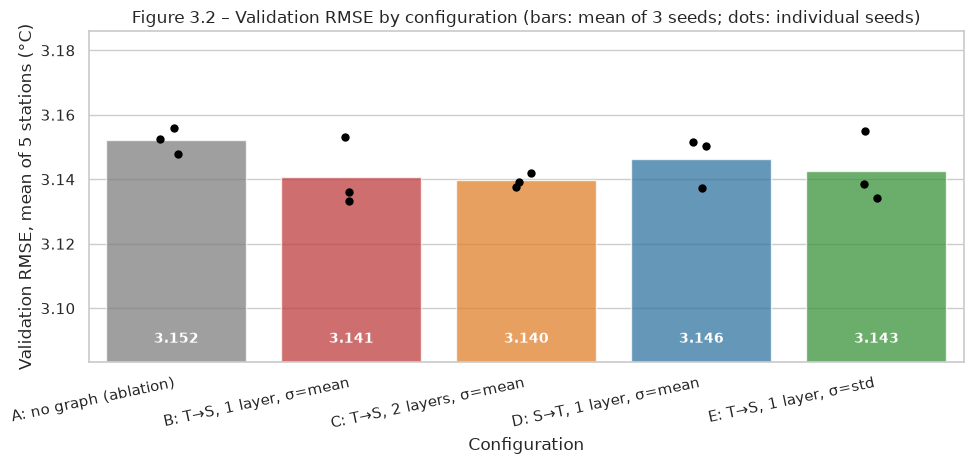

In [28]:
fig, ax = plt.subplots(figsize=(10, 4.8))
order_of_configs = list(CONFIGS)
colours = ["#7f7f7f", "#d62728", "#ff7f0e", "#1f77b4", "#2ca02c"]
sns.barplot(data=experiment_results, x="config", y="val_RMSE_mean_C", order=order_of_configs, palette=colours,
            errorbar=None, ax=ax, alpha=0.75, hue="config", legend=False)
sns.stripplot(data=experiment_results, x="config", y="val_RMSE_mean_C", order=order_of_configs, color="black",
              size=6, ax=ax)
low, high = experiment_results["val_RMSE_mean_C"].min(), experiment_results["val_RMSE_mean_C"].max()
ax.set_ylim(low - 0.05, high + 0.03)
for i, name in enumerate(order_of_configs):
    value = config_summary.loc[name, "mean val RMSE (°C)"]
    ax.text(i, low - 0.045, f"{value:.3f}", ha="center", va="bottom", fontsize=10, fontweight="bold", color="white")
ax.set_xlabel("Configuration")
ax.set_ylabel("Validation RMSE, mean of 5 stations (°C)")
ax.set_title("Figure 3.2 – Validation RMSE by configuration (bars: mean of 3 seeds; dots: individual seeds)")
plt.setp(ax.get_xticklabels(), rotation=12, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_validation_rmse_by_config.png", dpi=150)
plt.show()

Configuration B had the lowest RMSE of all of them for one of the seeds but Configuration C (temporal then spatial, 2 layers, σ = 78.9km) gave the lowest mean of all 3 seeds and a much tighter standard deviation across the seeds.  As mentioned before, the differences are very small.

The final configuration is selected here, with details, using the lowest mean RMSE on validation data.

In [29]:
graph_configs = [c for c in CONFIGS if not c.startswith("A")]
FINAL_CONFIG = config_summary.loc[graph_configs, "mean val RMSE (°C)"].idxmin()
config_runs = experiment_results[experiment_results["config"] == FINAL_CONFIG]
FINAL_SEED = int(config_runs.loc[config_runs["val_RMSE_mean_C"].idxmin(), "seed"])
final_order, final_layers, final_adjacency = CONFIGS[FINAL_CONFIG]

final_model = GNNRNNForecaster(final_order, final_layers, final_adjacency)
final_model.load_state_dict(torch.load(f"{run_file(FINAL_CONFIG, FINAL_SEED)}.pt"))
final_model.eval()
final_history = pd.read_csv(f"{run_file(FINAL_CONFIG, FINAL_SEED)}_history.csv")

# Matching ablation model (best seed of config A) for the spatial-information comparison
ablation_name = "A: no graph (ablation)"
ablation_runs = experiment_results[experiment_results["config"] == ablation_name]
ablation_seed = int(ablation_runs.loc[ablation_runs["val_RMSE_mean_C"].idxmin(), "seed"])
ablation_model = GNNRNNForecaster("T->S", 1, ADJ_NONE)
ablation_model.load_state_dict(torch.load(f"{run_file(ablation_name, ablation_seed)}.pt"))
ablation_model.eval()

torch.save(final_model.state_dict(), MODEL_DIR / "final_gnn_rnn_model.pt")
final_config = {
    "configuration": FINAL_CONFIG, "processing_order": final_order, "graph_layers": final_layers,
    "edge_weights": "Gaussian kernel exp(-(d/sigma)^2), row-normalised, no self-loops",
    "sigma_km": float(SIGMA_OPTIONS["mean" if "σ=mean" in FINAL_CONFIG else "std"]),
    "adjacency": final_adjacency.round(6).tolist(), "stations": STATIONS,
    "recurrent_cell": CELL_TYPE, "window_days": WINDOW, "hidden_size": HIDDEN_SIZE, "rnn_layers": NUM_LAYERS,
    "dropout": DROPOUT, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE, "patience": PATIENCE,
    "seed": FINAL_SEED, "scaling": "per-station StandardScaler from Part_1/models/feature_scalers.joblib",
    "validation_RMSE_mean_C": float(config_runs["val_RMSE_mean_C"].min()),
}
(MODEL_DIR / "final_gnn_rnn_config.json").write_text(json.dumps(final_config, indent=2, ensure_ascii=False))
config_table = pd.DataFrame({"value": {
    "Processing order": final_order, "Graph layers": final_layers,
    "Edge weights": f"Gaussian, σ = {final_config['sigma_km']:.1f} km, row-normalised",
    "Recurrent encoder": f"{CELL_TYPE}, {NUM_LAYERS} layers × {HIDDEN_SIZE} units, dropout {DROPOUT}",
    "Look-back window": f"{WINDOW} days", "Output": "Linear(64 → 7) per node (shared)",
    "Optimiser": f"Adam, lr {LEARNING_RATE}, batch {BATCH_SIZE}",
    "Early stopping": f"patience {PATIENCE}, best epoch {int(final_history.loc[final_history['val_loss'].idxmin(), 'epoch'])}",
    "Seed (best of 3)": FINAL_SEED,
    "Validation RMSE (mean of 5 stations)": f"{final_config['validation_RMSE_mean_C']:.3f} °C"}})
show_table(config_table, f"Table 3.9 – Final GNN+RNN configuration ({FINAL_CONFIG})")

**Table 3.9 – Final GNN+RNN configuration (C: T→S, 2 layers, σ=mean)**

,value
Processing order,T->S
Graph layers,2
Edge weights,"Gaussian, σ = 78.0 km, row-normalised"
Recurrent encoder,"GRU, 2 layers × 64 units, dropout 0.2"
Look-back window,60 days
Output,Linear(64 → 7) per node (shared)
Optimiser,"Adam, lr 0.001, batch 64"
Early stopping,"patience 10, best epoch 7"
Seed (best of 3),0
Validation RMSE (mean of 5 stations),3.138 °C


The best run was with the first seed, and this is the configuration that will be saved.
* Temporal → spatial order: better mean validation RMSE than spatial → temporal (3.141 vs 3.146 °C with one layer) and more stable training. It's also more intuitive: each station's 60-day history is first summarised into its standard weather state, and the stations then exchange these states. Mixing raw daily features before the GRU (S→T) blends signals of stations with different climates before the temporal patterns have been extracted doesn't work as well.
* Two graph layers: the lowest mean validation RMSE (3.138 °C) and by far the most consistent across seeds.  With two layers, information can also pass via an intermediate station (e.g. Ashburton → Christchurch Aero → Rangiora → Hanmer).
* σ = 78.0km: performed at least as well as the more local graph and keeps every station meaningfully connected, which suits a fully connected graph.
* GRU, 60-day window, 2 × 64 units, dropout 0.2, Adam (lr 0.001), batch 64, early stopping: carried over from Part 2, where they were selected on validation data.

Let's run that final model on each station, to forecast 7 day temperatures.  We'll use the same metrics, and use the scaler for each station.

In [30]:
def climatology_lookup(station):
    """Smoothed day-of-year mean temperature from the station's training period (°C) — as in Part 2."""
    train_start, train_end = split_dates["train"]
    train_temp = station_data[station].loc[train_start:train_end, TARGET]
    by_day = train_temp.groupby(train_temp.index.dayofyear).mean().reindex(range(1, 367)).interpolate()
    wrapped = pd.concat([by_day.iloc[-15:], by_day, by_day.iloc[:15]])
    return wrapped.rolling(31, center=True).mean().iloc[15:-15]

def error_metrics(forecast, observed):
    errors = forecast - observed
    return {"MAE_C": np.abs(errors).mean(), "RMSE_C": np.sqrt((errors ** 2).mean()),
            "R2": 1 - (errors ** 2).sum() / ((observed - observed.mean()) ** 2).sum(), "bias_C": errors.mean()}

X_test, y_test, test_dates = data_splits["test"]
observed_C = to_celsius(y_test.numpy())                              # [samples, nodes, 7]
gnn_forecast_C = to_celsius(predict(final_model, X_test).numpy())
ablation_forecast_C = to_celsius(predict(ablation_model, X_test).numpy())
target_days = pd.DatetimeIndex(np.array([test_dates + pd.Timedelta(days=h) for h in range(HORIZON)]).T.ravel())
climatology_C = np.stack([climatology_lookup(s).reindex(target_days.dayofyear).to_numpy().reshape(-1, HORIZON)
                          for s in STATIONS], axis=1)

def station_metrics_table(forecast_C, model_label):
    rows = []
    for k, station in enumerate(STATIONS):
        pooled = error_metrics(forecast_C[:, k], observed_C[:, k])
        rmse_by_day = np.sqrt(((forecast_C[:, k] - observed_C[:, k]) ** 2).mean(axis=0))
        clim_rmse = error_metrics(climatology_C[:, k], observed_C[:, k])["RMSE_C"]
        rows.append({"Station ID": STATION_INFO[station]["id"], "Station": station, "Model": model_label,
                     "MAE (°C)": pooled["MAE_C"], "RMSE (°C)": pooled["RMSE_C"], "R²": pooled["R2"],
                     "Bias (°C)": pooled["bias_C"], "RMSE t+1 (°C)": rmse_by_day[0],
                     "RMSE t+7 (°C)": rmse_by_day[-1], "Skill vs climatology": 1 - pooled["RMSE_C"] / clim_rmse})
    return pd.DataFrame(rows)

gnn_table = station_metrics_table(gnn_forecast_C, "GNN+RNN")
gnn_table.to_csv(MODEL_DIR / "test_results_gnn_rnn.csv", index=False)
metric_cols = ["MAE (°C)", "RMSE (°C)", "R²", "Bias (°C)", "RMSE t+1 (°C)", "RMSE t+7 (°C)", "Skill vs climatology"]
display(Markdown(f"**Table 3.10 – Test-set performance of the final GNN+RNN model ({FINAL_CONFIG}) at each station, "
                 f"2022-10-23 – 2025-9-30. All five stations were used for training, validation and testing.**"))
display(gnn_table.drop(columns="Model").style.format({c: "{:.3f}" for c in metric_cols}).hide(axis="index"))
print(f"Mean over the five stations: RMSE {gnn_table['RMSE (°C)'].mean():.3f} °C, "
      f"MAE {gnn_table['MAE (°C)'].mean():.3f} °C")

**Table 3.10 – Test-set performance of the final GNN+RNN model (C: T→S, 2 layers, σ=mean) at each station, 2022-10-23 – 2025-9-30. All five stations were used for training, validation and testing.**

Station ID,Station,MAE (°C),RMSE (°C),R²,Bias (°C),RMSE t+1 (°C),RMSE t+7 (°C),Skill vs climatology
4843,Christchurch Aero,2.433,3.028,0.625,0.283,2.606,3.117,0.013
24120,Chch Kyle Street,2.289,2.884,0.654,0.340,2.451,2.974,0.013
26170,Ashburton Aero,2.515,3.129,0.579,0.125,2.735,3.212,0.016
17244,Rangiora,2.334,2.925,0.609,0.306,2.539,3.002,0.012
11234,Hanmer Forest,2.750,3.458,0.608,0.210,2.905,3.549,0.032


Mean over the five stations: RMSE 3.085 °C, MAE 2.464 °C


This shows a very slight improvement over Part 2 results for most of the stations, most significantly for Hanmer Forest bias (from 1.306 to 0.210 degrees) because it was trained based on Hanmer data.  For all stations this model is slightly better than the climate/seasonal forecasts, although Christchurch Aero and Chch Kyle Street did fractionally worse than in Part 2 (from 0.021 and 0.023 to 0.013 and 0.013 respectively for skill versus climatology).

How does the forecast look by day?

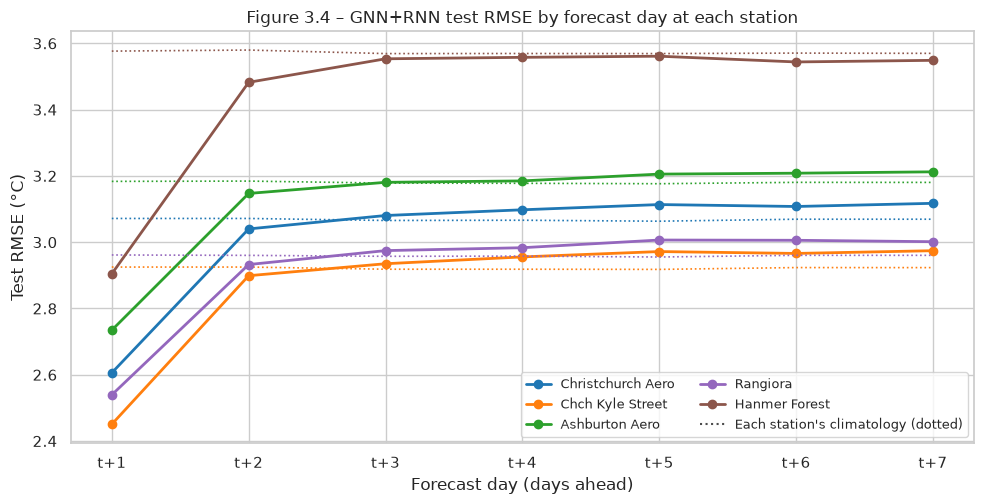

In [31]:
station_colours = dict(zip(STATIONS, ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", "#8c564b"]))
lead_days = np.arange(1, HORIZON + 1)
fig, ax = plt.subplots(figsize=(10, 5.2))
for k, station in enumerate(STATIONS):
    rmse_by_day = np.sqrt(((gnn_forecast_C[:, k] - observed_C[:, k]) ** 2).mean(axis=0))
    clim_by_day = np.sqrt(((climatology_C[:, k] - observed_C[:, k]) ** 2).mean(axis=0))
    ax.plot(lead_days, rmse_by_day, marker="o", lw=2, color=station_colours[station], label=station)
    ax.plot(lead_days, clim_by_day, ls=":", lw=1.2, color=station_colours[station])
ax.plot([], [], ls=":", color="0.3", label="Each station's climatology (dotted)")
ax.set_xticks(lead_days)
ax.set_xticklabels([f"t+{d}" for d in lead_days])
ax.set_xlabel("Forecast day (days ahead)")
ax.set_ylabel("Test RMSE (°C)")
ax.set_title("Figure 3.4 – GNN+RNN test RMSE by forecast day at each station")
ax.legend(fontsize=9, ncol=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_gnn_test_rmse_by_forecast_day.png", dpi=150)
plt.show()

Again, this shows that the first couple of days of forecast temperatures are consistently better than climate/seasonal but get less accurate after that - with the exception being Hanmer Forest.  Again, the difference is tiny (see the y-axis scale).

**3.5 Summary and Comparison**
For a direct comparison with the RNN model in Part 2 we'll rerun that model - with Christchurch Aero training and scaler applied to all stations - against the GNN+RNN model developed above - with each station's scaler and training.  We'll use the Test dataset for the evaluation.

In [32]:
class Part2Forecaster(nn.Module):
    """The Part 2 single-station model (same definition as in Part 2)."""

    def __init__(self, cell_type, n_features=len(FEATURES), hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS,
                 dropout=DROPOUT, horizon=HORIZON):
        super().__init__()
        recurrent_class = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell_type]
        self.recurrent = recurrent_class(n_features, hidden_size, num_layers=num_layers, dropout=dropout,
                                         batch_first=True)
        self.head = nn.Linear(hidden_size, horizon)

    def forward(self, x):
        sequence_output, _ = self.recurrent(x)
        return self.head(sequence_output[:, -1])


part2_model = Part2Forecaster(part2_config["cell_type"])
part2_model.load_state_dict(torch.load(PART2_MODEL_DIR / "final_model.pt"))
part2_model.eval()
source_scaler = station_scalers[part2_config["source_station"]]
src_mean, src_std = source_scaler.mean_[TARGET_IDX], source_scaler.scale_[TARGET_IDX]

part2_forecast_C = np.zeros_like(observed_C)
for k, station in enumerate(STATIONS):
    scaled_src = source_scaler.transform(station_data[station][FEATURES])
    X_station = torch.tensor(np.array([scaled_src[dates.get_loc(d) - WINDOW: dates.get_loc(d)] for d in test_dates]),
                             dtype=torch.float32)
    with torch.no_grad():
        part2_forecast_C[:, k] = part2_model(X_station).numpy() * src_std + src_mean

rnn_table = station_metrics_table(part2_forecast_C, "RNN (Part 2)")
saved_part2 = pd.read_csv(PART2_MODEL_DIR / "test_comparison_table.csv")
max_difference = np.abs(rnn_table["RMSE (°C)"].to_numpy() - saved_part2["RMSE (°C)"].to_numpy()).max()
print(f"Largest difference from the RMSEs saved in Part 2: {max_difference:.2e} °C")

Largest difference from the RMSEs saved in Part 2: 1.01e-08 °C


Confirmed that the model is pretty much exactly the one we used in Part 2.

Let's run the comparison.

In [33]:
# For each station, lay out the RNN row followed by the GNN+RNN row
comparison = pd.concat([pd.concat([rnn_table.iloc[[k]], gnn_table.iloc[[k]]]) for k in range(N_NODES)])
comparison["Part 2 role"] = np.where(comparison["Station"] == part2_config["source_station"],
                                     "source (train + validation)", "test only")
comparison = comparison.reset_index(drop=True)[["Station ID", "Station", "Part 2 role", "Model"] + metric_cols]
comparison.to_csv(MODEL_DIR / "test_comparison_rnn_vs_gnn.csv", index=False)

def shade_gnn_rows(row):
    return ["background-color: #eef6ee" if row["Model"] == "GNN+RNN" else "" for _ in row]

display(Markdown("**Table 3.11 – Test-set comparison of the Part 2 RNN and the Part 3 GNN+RNN at each station "
                 "(23 Oct 2022 – 30 Sep 2025, same samples and metrics)**"))
display(comparison.style.apply(shade_gnn_rows, axis=1).format({c: "{:.3f}" for c in metric_cols}).hide(axis="index"))

change = pd.DataFrame({
    "Station ID": [STATION_INFO[s]["id"] for s in STATIONS], "Station": STATIONS,
    "RMSE RNN (°C)": rnn_table["RMSE (°C)"].to_numpy(), "RMSE GNN+RNN (°C)": gnn_table["RMSE (°C)"].to_numpy(),
    "Change in RMSE (°C)": gnn_table["RMSE (°C)"].to_numpy() - rnn_table["RMSE (°C)"].to_numpy(),
    "Change in RMSE (%)": 100 * (gnn_table["RMSE (°C)"].to_numpy() / rnn_table["RMSE (°C)"].to_numpy() - 1),
    "Bias RNN (°C)": rnn_table["Bias (°C)"].to_numpy(), "Bias GNN+RNN (°C)": gnn_table["Bias (°C)"].to_numpy(),
})
show_table(change.round(3), "Table 3.12 – Change in test RMSE and bias from RNN to GNN+RNN (negative change = improvement)")

**Table 3.11 – Test-set comparison of the Part 2 RNN and the Part 3 GNN+RNN at each station (23 Oct 2022 – 30 Sep 2025, same samples and metrics)**

Station ID,Station,Part 2 role,Model,MAE (°C),RMSE (°C),R²,Bias (°C),RMSE t+1 (°C),RMSE t+7 (°C),Skill vs climatology
4843,Christchurch Aero,source (train + validation),RNN (Part 2),2.407,3.004,0.631,0.244,2.622,3.089,0.021
4843,Christchurch Aero,source (train + validation),GNN+RNN,2.433,3.028,0.625,0.283,2.606,3.117,0.013
24120,Chch Kyle Street,test only,RNN (Part 2),2.242,2.853,0.661,-0.001,2.477,2.932,0.023
24120,Chch Kyle Street,test only,GNN+RNN,2.289,2.884,0.654,0.340,2.451,2.974,0.013
26170,Ashburton Aero,test only,RNN (Part 2),2.529,3.140,0.576,0.307,2.758,3.220,0.013
26170,Ashburton Aero,test only,GNN+RNN,2.515,3.129,0.579,0.125,2.735,3.212,0.016
17244,Rangiora,test only,RNN (Part 2),2.377,2.965,0.598,0.618,2.696,2.998,-0.002
17244,Rangiora,test only,GNN+RNN,2.334,2.925,0.609,0.306,2.539,3.002,0.012
11234,Hanmer Forest,test only,RNN (Part 2),3.020,3.715,0.548,1.306,3.184,3.757,-0.040
11234,Hanmer Forest,test only,GNN+RNN,2.750,3.458,0.608,0.210,2.905,3.549,0.032


**Table 3.12 – Change in test RMSE and bias from RNN to GNN+RNN (negative change = improvement)**

,Station ID,Station,RMSE RNN (°C),RMSE GNN+RNN (°C),Change in RMSE (°C),Change in RMSE (%),Bias RNN (°C),Bias GNN+RNN (°C)
0,4843,Christchurch Aero,3.004,3.028,0.024,0.790,0.244,0.283
1,24120,Chch Kyle Street,2.853,2.884,0.031,1.084,-0.001,0.340
2,26170,Ashburton Aero,3.140,3.129,-0.011,-0.352,0.307,0.125
3,17244,Rangiora,2.965,2.925,-0.040,-1.350,0.618,0.306
4,11234,Hanmer Forest,3.715,3.458,-0.257,-6.925,1.306,0.210


* Hanmer Forest has improved significantly: RMSE falls from 3.72 to 3.46°C (−6.9%), R² rises from 0.55 to 0.61, the bias drops from +1.31 to +0.21°C, and skill against climatology turns from −4.0% to +3.2%.
* Rangiora and Ashburton Aero improve a little (1.4% and 0.4% decrease in RMSE), mainly through smaller biases.
* Christchurch Aero and Chch Kyle Street get slightly worse (0.7% and 1.1% increase in RMSE). The Part 2 RNN was trained only on Christchurch Aero, so it is the specialist for that climate, which also fits neighbouring Kyle Street. The GNN+RNN must share its weights across five different climates, which probably pulled the Christchurch results away from the Christchurch Aero specific training. Kyle Street's bias also grew from 0.00 to +0.34°C.
* Averaged over the five stations, though, the GNN+RNN is better (with an RMSE of 3.08 versus 3.14°C for the RNN). Above all, it is more uniform - no station is left with a large bias.

How do the models compare - per station and per day?

In [34]:
ablation_table = station_metrics_table(ablation_forecast_C, "No-graph ablation")
decomposition = pd.DataFrame({
    "RNN Part 2": rnn_table["RMSE (°C)"].to_numpy(),
    "No-graph ablation": ablation_table["RMSE (°C)"].to_numpy(),
    "GNN+RNN": gnn_table["RMSE (°C)"].to_numpy(),
}, index=STATIONS)
decomposition["Δ multi-station training"] = decomposition["No-graph ablation"] - decomposition["RNN Part 2"]
decomposition["Δ spatial graph"] = decomposition["GNN+RNN"] - decomposition["No-graph ablation"]
decomposition.loc["Mean of 5 stations"] = decomposition.mean()
show_table(decomposition.round(3), "Table 3.13 – Test RMSE (°C) of the three models and the two contributions "
                                   "(negative Δ = lower error)")

rmse_by_day = {}
for label, forecast in [("RNN Part 2", part2_forecast_C), ("No-graph ablation", ablation_forecast_C),
                        ("GNN+RNN", gnn_forecast_C)]:
    rmse_by_day[label] = np.sqrt(((forecast - observed_C) ** 2).mean(axis=(0, 1)))
rmse_by_day["Climatology"] = np.sqrt(((climatology_C - observed_C) ** 2).mean(axis=(0, 1)))
show_table(pd.DataFrame(rmse_by_day, index=[f"t+{d}" for d in lead_days]).T.round(3),
           "Table 3.14 – Test RMSE (°C) by forecast day, average of all five stations")

**Table 3.13 – Test RMSE (°C) of the three models and the two contributions (negative Δ = lower error)**

,RNN Part 2,No-graph ablation,GNN+RNN,Δ multi-station training,Δ spatial graph
Christchurch Aero,3.004,3.023,3.028,0.018,0.005
Chch Kyle Street,2.853,2.883,2.884,0.029,0.002
Ashburton Aero,3.140,3.109,3.129,-0.031,0.020
Rangiora,2.965,2.908,2.925,-0.057,0.017
Hanmer Forest,3.715,3.461,3.458,-0.254,-0.003
Mean of 5 stations,3.136,3.077,3.085,-0.059,0.008


**Table 3.14 – Test RMSE (°C) by forecast day, average of all five stations**

,t+1,t+2,t+3,t+4,t+5,t+6,t+7
RNN Part 2,2.758,3.155,3.234,3.247,3.208,3.208,3.213
No-graph ablation,2.659,3.101,3.147,3.164,3.161,3.166,3.154
GNN+RNN,2.652,3.107,3.153,3.163,3.179,3.173,3.178
Climatology,3.152,3.153,3.147,3.147,3.145,3.150,3.149


* Multi-station training with per-station scaling explains the whole improvement over Part 2 - mean test RMSE for all stations falls from 3.136 to 3.077°C. The gain is mostly at Hanmer Forest (−0.25°C), with smaller gains at Rangiora and Ashburton, and small losses at the two Christchurch stations.
* The spatial graph itself adds nothing measurable on the test set. The change from the ablation to the GNN+RNN is between −0.003 and +0.019°C per station, +0.008°C on average. That is within the noise between random seeds, and opposite to the small validation advantage (Table 3.8).
* By forecast day (Table 3.14), the graph models and the ablation share the same advantage over the Part 2 RNN at t+1 (2.65 vs 2.76 °C pooled, ≈ 4 % better). From t+3 all three models' predictions were slightly worse than climatology.

How does that look?

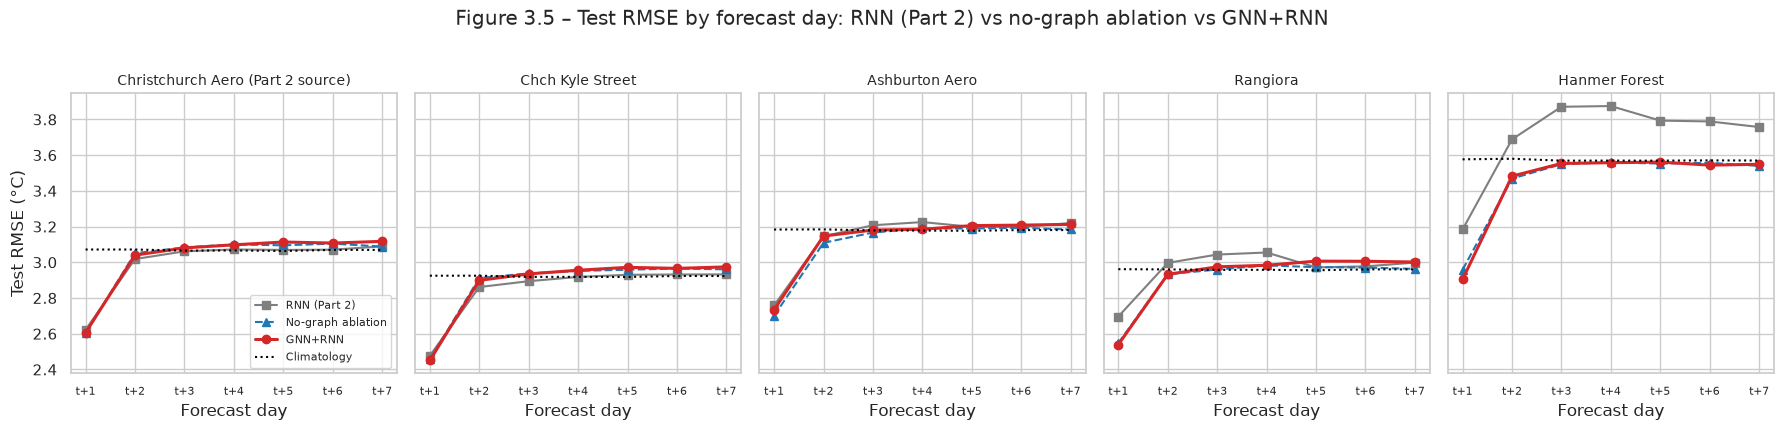

In [35]:
fig, axes = plt.subplots(1, N_NODES, figsize=(18, 4.2), sharey=True)
for k, (ax, station) in enumerate(zip(axes, STATIONS)):
    for label, forecast, style in [("RNN (Part 2)", part2_forecast_C, dict(color="#7f7f7f", marker="s")),
                                   ("No-graph ablation", ablation_forecast_C, dict(color="#1f77b4", marker="^", ls="--")),
                                   ("GNN+RNN", gnn_forecast_C, dict(color="#d62728", marker="o", lw=2.2))]:
        ax.plot(lead_days, np.sqrt(((forecast[:, k] - observed_C[:, k]) ** 2).mean(axis=0)), label=label, **style)
    ax.plot(lead_days, np.sqrt(((climatology_C[:, k] - observed_C[:, k]) ** 2).mean(axis=0)), color="black",
            ls=":", label="Climatology")
    ax.set_title(f"{station}{' (Part 2 source)' if station == part2_config['source_station'] else ''}", fontsize=10)
    ax.set_xticks(lead_days)
    ax.set_xticklabels([f"t+{d}" for d in lead_days], fontsize=8)
    ax.set_xlabel("Forecast day")
axes[0].set_ylabel("Test RMSE (°C)")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Figure 3.5 – Test RMSE by forecast day: RNN (Part 2) vs no-graph ablation vs GNN+RNN", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_rnn_vs_gnn_by_forecast_day.png", dpi=150, bbox_inches="tight")
plt.show()

The GNN+RNN and ablation (no graph) models are pretty much the same, with a small variation from the Part 2 RNN, but the graph shows a clear improvement for Hanmer.  The GNN+RNN and ablations models are consistently better at predicting temperatures for all stations one to two days ahead, but the climate/season predictions are better in the longer run.

**Summary**
*Graph and model*
* Five stations as nodes of a fully connected, undirected graph. Haversine distances range from 7 km (Christchurch Aero–Kyle Street) to 174 km (Ashburton–Hanmer). Edge weights use a Gaussian kernel(σ = 78.0 km) and are row-normalised.
* Each node uses the same 8 features over the same 60-day window as Part 2; the target is daily mean temperature t+1 to t+7 at every node.
* Final configuration: a shared 2-layer GRU (64 units) encodes each station's history; two graph layers (separate self and neighbour weights, residual connections) exchange information between stations; a shared linear head outputs the 7-day forecast at every node. Training uses Adam (lr 0.001), batch 64 and early stopping, with per-station scaling.
* Evidence for the configuration (validation, 3 seeds each): temporal then spatial beat spatial then temporal (3.141 vs 3.146°C), two graph layers beat one (3.138°C, most stable across seeds), and σ = 78.0 km was at least as good as the more local σ = 48.5 km. All graph variants beat the no-graph ablation on validation (3.152°C), but by 0.014°C or less.

*Test results (2022-10-23 to 2025-9-30)*
* GNN+RNN test RMSE ranged from 2.88 to 3.46°C per station (with a mean of 3.08°C). Biases are small everywhere (+0.13 to +0.34 °C), and the model beats each station's climatology at all five stations.
* Compared with the Part 2 RNN, mean RMSE falls from 3.14 to 3.08°C. Hanmer Forest gains the most (RMSE goes from 3.72 to 3.46°C; bias drops from +1.31 to +0.21°C), Rangiora and Ashburton improve slightly, and the two Christchurch stations are slightly worse (+0.02 and 0.03°C), where the Part 2 specialist model had the advantage.
* The improvement is largest at t+1 (pooled 2.76 → 2.65 °C). From t+3 every model is very close to the climate/season level.

*Effect of spatial information*
* The no-graph ablation shows that the gains over Part 2 come from training one model on all five stations with per-station scaling, not from the graph. On the test set the graph changed RMSE by only +0.008°C on average (−0.003 to +0.019°C per station), which is within the noise between seeds.
* Why the graph adds so little here:
  1. The stations are already highly correlated (r = 0.92–0.98), so a neighbour's data largely repeats what the station already knows.
  2. At a daily time step, a weather system usually crosses the 7–174 km network within hours, so it reaches all stations on the same day and a neighbour offers no lead time.
  3. Beyond 2–3 days, temperature depends on weather systems that are still hundreds or thousands of kilometres away, outside this small network.
* Key differences between the models: The RNN is a single-station specialist (slightly better at its own station and its close neighbour, poor for the more distant stations). The GNN+RNN is a single model that forecasts the whole network at once, with consistent, low-bias performance across all stations.  Spatial information would be more valuable with a larger network, sub-daily data, or upstream stations further west and south.